# ARTI 502 | Deep Learning: 1st Assignment

## Training-Testing Neural Net with MNIST Dataset using Pytorch

### Task 1

In [1]:
%pip install torch torchvision matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


### Task 2

In [3]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("/nTraining dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

print("MNIST loaded successfully!")

/nTraining dataset size: 60000
Testing dataset size: 10000
MNIST loaded successfully!


### Task 3

In [4]:
image, label = train_dataset[0]

print("Image tensor size:", image.shape)
print("Image label:", label)

Image tensor size: torch.Size([1, 28, 28])
Image label: 5


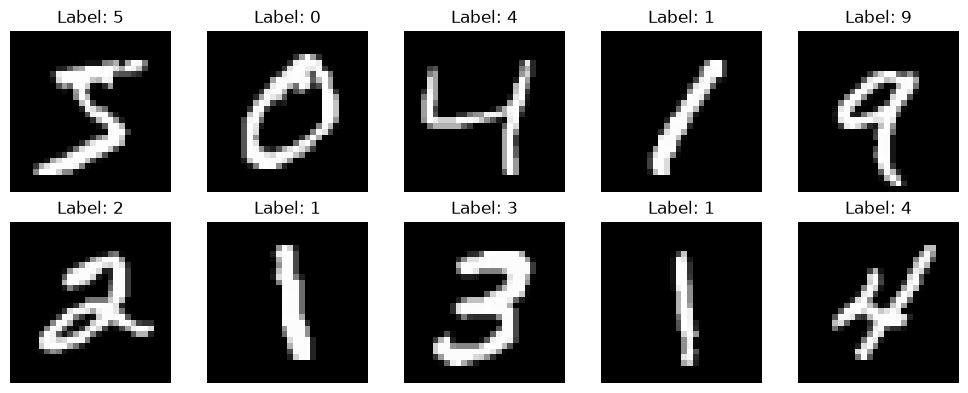

In [5]:
plt.figure(figsize=(10, 4))

for i in range(10):
    image, label = train_dataset[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Label: {label}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Task 4

In [6]:
from torch.utils.data import DataLoader

In [7]:
# Create DataLoaders with a batch size of 32 (for the 32 x 1 x 28 x 28 shape)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [8]:
# Define the Neural Network Architecture
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        # Input features: 28 * 28 = 784, Hidden layer neurons: 128, Output classes: 10 (digits 0-9)
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Flatten the input tensor from (32 x 1 x 28 x 28) to (32 x 784)
        x = torch.flatten(x, start_dim=1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

In [9]:
# Instantiate the network
net = SimpleNN()
print(net)

SimpleNN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [10]:
# Verify the flattening shape with a mini batch
images, labels = next(iter(train_loader))
print("Original batch tensor shape:", images.shape)
flattened_images = torch.flatten(images, start_dim=1)
print("Flattened batch tensor shape:", flattened_images.shape)

Original batch tensor shape: torch.Size([32, 1, 28, 28])
Flattened batch tensor shape: torch.Size([32, 784])


### Task 5

In [11]:
def train(net, train_loader, epochs=5, learning_rate=0.01, momentum=0.9, print_every=200):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=momentum)

    batch_losses = []   # loss of every mini-batch
    epoch_losses = []   # average loss per epoch
    epoch_accs = []     # accuracy per epoch

    net.train()
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader, start=1):
            optimizer.zero_grad()              # reset gradients
            outputs = net(images)              # forward pass
            loss = criterion(outputs, labels)  # calculate the loss
            loss.backward()                    # backpropagation
            optimizer.step()                   # update the weights

            batch_losses.append(loss.item())   # store mini-batch loss
            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

            if batch_idx % print_every == 0:
                print(f"Epoch {epoch + 1}/{epochs}, Batch {batch_idx}/{len(train_loader)}, "
                      f"Loss: {loss.item():.4f}, Accuracy: {100 * correct / total:.2f}%")

        epoch_loss = running_loss / total
        epoch_acc = 100 * correct / total
        epoch_losses.append(epoch_loss)
        epoch_accs.append(epoch_acc)
        print(f"==> Epoch {epoch + 1}/{epochs} done, Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%\n")

    return batch_losses, epoch_losses, epoch_accs

### TASK 6

Epoch 1/5, Batch 200/1875, Loss: 0.6093, Accuracy: 73.19%
Epoch 1/5, Batch 400/1875, Loss: 0.2913, Accuracy: 80.98%
Epoch 1/5, Batch 600/1875, Loss: 0.3119, Accuracy: 83.81%
Epoch 1/5, Batch 800/1875, Loss: 0.1568, Accuracy: 85.43%
Epoch 1/5, Batch 1000/1875, Loss: 0.1010, Accuracy: 86.75%
Epoch 1/5, Batch 1200/1875, Loss: 0.3653, Accuracy: 87.83%
Epoch 1/5, Batch 1400/1875, Loss: 0.3636, Accuracy: 88.51%
Epoch 1/5, Batch 1600/1875, Loss: 0.0975, Accuracy: 89.15%
Epoch 1/5, Batch 1800/1875, Loss: 0.1242, Accuracy: 89.65%
==> Epoch 1/5 done, Loss: 0.3583, Accuracy: 89.81%

Epoch 2/5, Batch 200/1875, Loss: 0.1103, Accuracy: 94.48%
Epoch 2/5, Batch 400/1875, Loss: 0.1411, Accuracy: 94.48%
Epoch 2/5, Batch 600/1875, Loss: 0.1028, Accuracy: 94.52%
Epoch 2/5, Batch 800/1875, Loss: 0.2102, Accuracy: 94.66%
Epoch 2/5, Batch 1000/1875, Loss: 0.0965, Accuracy: 94.77%
Epoch 2/5, Batch 1200/1875, Loss: 0.1413, Accuracy: 94.91%
Epoch 2/5, Batch 1400/1875, Loss: 0.1642, Accuracy: 95.00%
Epoch 2/5, B

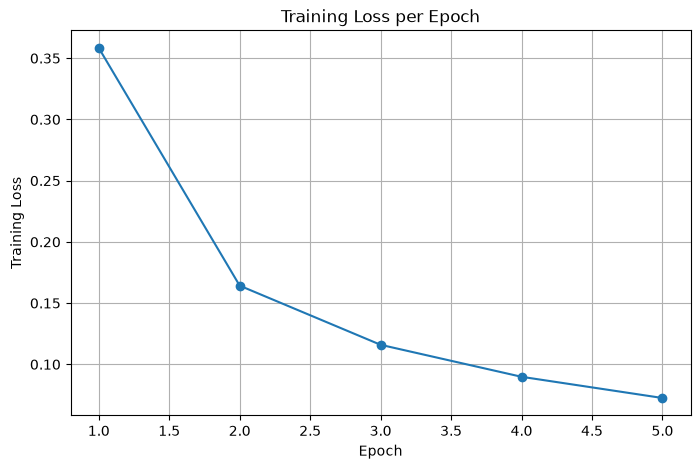

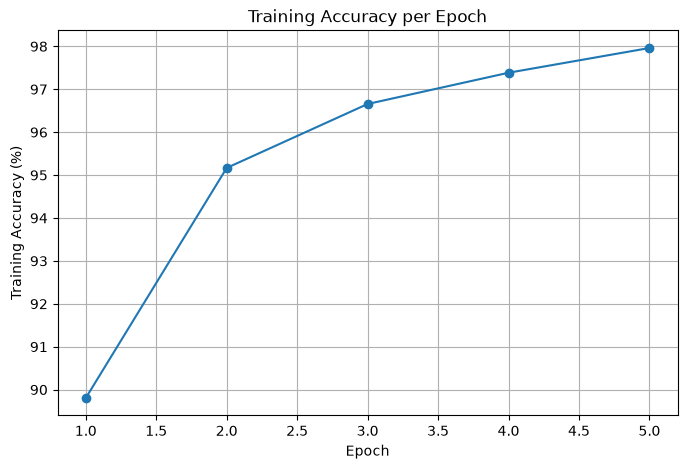

In [12]:

batch_losses, epoch_losses, epoch_accs = train(
    net,
    train_loader,
    epochs=5,
    learning_rate=0.01,
    momentum=0.9,
    print_every=200
)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss per Epoch")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(epoch_accs) + 1), epoch_accs, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy per Epoch")
plt.grid(True)
plt.show()


### TASK 7

In [13]:

net.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = net(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 97.44%
Correct predictions: 9744/10000


### TASK 8

In [14]:
# Define tuning search space
learning_rates = [0.005, 0.01, 0.05]
momentums = [0.8, 0.9]
hidden_neuron_sizes = [64, 128, 256]

best_loss = float('inf')
best_acc = 0.0
best_params = {}

print("Starting Parameter and Architecture Tuning...\n")

for lr in learning_rates:
    for mom in momentums:
        for neurons in hidden_neuron_sizes:
            
            # Define architecture dynamically
            class TunedNN(nn.Module):
                def __init__(self, hidden_size):
                    super(TunedNN, self).__init__()
                    self.fc1 = nn.Linear(28 * 28, hidden_size)
                    self.relu = nn.ReLU()
                    self.fc2 = nn.Linear(hidden_size, 10)

                def forward(self, x):
                    x = torch.flatten(x, start_dim=1)
                    x = self.fc1(x)
                    x = self.relu(x)
                    x = self.fc2(x)
                    return x

            model = TunedNN(neurons)
            
            # Quick 2-epoch training run for evaluation during tuning
            criterion = nn.CrossEntropyLoss()
            optimizer = optim.SGD(model.parameters(), lr=lr, momentum=mom)
            
            model.train()
            running_loss = 0.0
            correct = 0
            total = 0
            
            for epoch in range(2): # 2 epochs for swift grid search evaluation
                for images, labels in train_loader:
                    optimizer.zero_grad()
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    loss.backward()
                    optimizer.step()
                    
                    running_loss += loss.item() * images.size(0)
                    correct += (outputs.argmax(dim=1) == labels).sum().item()
                    total += labels.size(0)
            
            epoch_loss = running_loss / total
            epoch_acc = 100 * correct / total
            
            print(f"LR: {lr}, Momentum: {mom}, Neurons: {neurons} ==> Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%")
            
            # Track best configuration based on lowest loss and highest accuracy
            if epoch_loss < best_loss or epoch_acc > best_acc:
                best_loss = epoch_loss
                best_acc = epoch_acc
                best_params = {"lr": lr, "momentum": mom, "neurons": neurons}

print("\n==============================================")
print(f"BEST CONFIGURATION FOUND:")
print(f"Learning Rate : {best_params['lr']}")
print(f"Momentum      : {best_params['momentum']}")
print(f"Hidden Neurons: {best_params['neurons']}")
print(f"Lowest Loss   : {best_loss:.4f}")
print(f"Highest Acc   : {best_acc:.2f}%")
print("==============================================")

Starting Parameter and Architecture Tuning...

LR: 0.005, Momentum: 0.8, Neurons: 64 ==> Loss: 0.4362, Accuracy: 88.49%
LR: 0.005, Momentum: 0.8, Neurons: 128 ==> Loss: 0.4364, Accuracy: 88.54%
LR: 0.005, Momentum: 0.8, Neurons: 256 ==> Loss: 0.4306, Accuracy: 88.81%
LR: 0.005, Momentum: 0.9, Neurons: 64 ==> Loss: 0.3415, Accuracy: 90.58%
LR: 0.005, Momentum: 0.9, Neurons: 128 ==> Loss: 0.3438, Accuracy: 90.49%
LR: 0.005, Momentum: 0.9, Neurons: 256 ==> Loss: 0.3312, Accuracy: 90.95%
LR: 0.01, Momentum: 0.8, Neurons: 64 ==> Loss: 0.3506, Accuracy: 90.27%
LR: 0.01, Momentum: 0.8, Neurons: 128 ==> Loss: 0.3374, Accuracy: 90.82%
LR: 0.01, Momentum: 0.8, Neurons: 256 ==> Loss: 0.3276, Accuracy: 91.00%
LR: 0.01, Momentum: 0.9, Neurons: 64 ==> Loss: 0.2767, Accuracy: 92.04%
LR: 0.01, Momentum: 0.9, Neurons: 128 ==> Loss: 0.2599, Accuracy: 92.62%
LR: 0.01, Momentum: 0.9, Neurons: 256 ==> Loss: 0.2524, Accuracy: 92.92%
LR: 0.05, Momentum: 0.8, Neurons: 64 ==> Loss: 0.2014, Accuracy: 93.96%
LR: